# Sobol sensitivity analysis


## 1. Setup


In [1]:
from pathlib import Path
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from utilities.residual_orponet import ResidualOrPoNet
from utilities.function_library import sobol_g_star
from utilities.training import Trainer


In [2]:
TORCH_SEED = 5678


DEVICE = torch.device("cpu")
DTYPE = torch.float32

torch.manual_seed(TORCH_SEED)


## 2. Function and data


In [3]:
DIMENSION = 100
ALPHA = 0.5  # sobol g* parameter
DATASET_SEED = 1234
TRAIN_SAMPLES = 8000
VALIDATION_SAMPLES = 2000
TEST_SAMPLES = 2000

a = torch.linspace(0, 10, DIMENSION, dtype=torch.float64, device=DEVICE)
delta = torch.tensor(
    np.random.RandomState(DATASET_SEED).rand(DIMENSION),
    dtype=torch.float64,
    device=DEVICE,
)

rng = np.random.default_rng(DATASET_SEED)

physical_points = torch.from_numpy(
    rng.random((TRAIN_SAMPLES + VALIDATION_SAMPLES + TEST_SAMPLES, DIMENSION))
).to(DEVICE)

targets = sobol_g_star(physical_points, a=a, delta=delta, alpha=ALPHA)

inputs = (2 * physical_points - 1).to(DTYPE)
validation_end = TRAIN_SAMPLES + VALIDATION_SAMPLES

train_x, train_y = inputs[:TRAIN_SAMPLES], targets[:TRAIN_SAMPLES]
validation_x, validation_y = (
    inputs[TRAIN_SAMPLES:validation_end],
    targets[TRAIN_SAMPLES:validation_end],
)

test_x, test_y = inputs[validation_end:], targets[validation_end:]
target_mean = train_y.mean()
target_std = train_y.std(unbiased=False)

standardized_train_y = ((train_y - target_mean) / target_std).to(DTYPE)
standardized_validation_y = ((validation_y - target_mean) / target_std).to(DTYPE)


## 3. Model and training


In [4]:
DEGREE = 6


In [ ]:
torch.manual_seed(TORCH_SEED)
model = ResidualOrPoNet(
    basis_configs=[
        {"type": "legendre", "degree": DEGREE, "constant_channels": 2}
        for _ in range(DIMENSION)
    ],
    data_domain_lb=[-1] * DIMENSION,
    data_domain_ub=[1] * DIMENSION,
    training_domain_lb=[-1] * DIMENSION,
    training_domain_ub=[1] * DIMENSION,
    neuron_copies=1,
    normalize_basis=True,
    use_additive_basis_branch=True,
    gate_config=None,
    dtype=DTYPE,
).to(DEVICE)

torch.manual_seed(TORCH_SEED)

# initialize the additive branch weights mainly. Can be removed.
with torch.no_grad():
    for layer in model._hidden_layers[1:]:
        for weight in [layer.projection_w, layer.basis_projection]:
            weight.copy_(torch.randn_like(weight) / math.sqrt(weight.shape[0]))
    weight = model._output_weight
    weight.copy_(
        torch.randn_like(weight) / math.sqrt(weight.shape[1] * weight.shape[2])
    )

# basis-aware initialization.
model.apply_basis_aware_init(train_x, gain=0.1)


In [7]:
train_loader = DataLoader(
    TensorDataset(train_x, standardized_train_y),
    batch_size=128,
    shuffle=True,
    drop_last=True,
    generator=torch.Generator().manual_seed(TORCH_SEED),
)

validation_loader = DataLoader(
    TensorDataset(validation_x, standardized_validation_y),
    batch_size=4096,
    shuffle=False,
)

trainer = Trainer(
    model,
    (train_x, train_y),
    (validation_x, validation_y),
    target_stats=(target_mean, target_std),
    selection="validation_loss",
    validation_batches=validation_loader,
)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, amsgrad=True)

trainer.fit(
    optimizer,
    epochs=500,
    batches=train_loader,
    early_stopping={"patience": 10, "grace": 100},
    log_every=25,
)

trainer.restore_best()
history = trainer.history


adam 1: validation MSE=2.379e+00
adam 25: validation MSE=5.896e-01
adam 50: validation MSE=4.854e-01
adam 75: validation MSE=4.484e-01
adam 100: validation MSE=5.036e-01


## 4. Learning curves


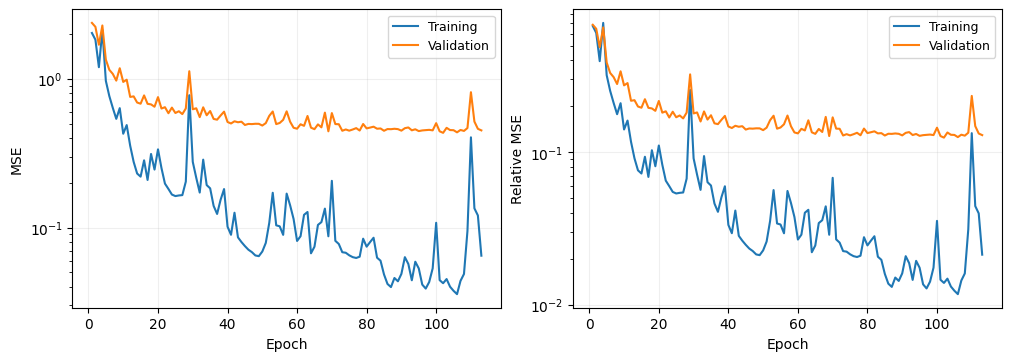

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)

axes[0].semilogy(
    history["update"], history["train_mse"], label="Training", linewidth=1.5
)
axes[0].semilogy(
    history["update"], history["validation_mse"], label="Validation", linewidth=1.5
)

axes[0].set(xlabel="Epoch", ylabel="MSE")
axes[0].grid(alpha=0.2)
axes[0].legend(fontsize=9)

axes[1].semilogy(
    history["update"],
    history["train_relative_l2"] ** 2,
    label="Training",
    linewidth=1.5,
)
axes[1].semilogy(
    history["update"],
    history["validation_relative_l2"] ** 2,
    label="Validation",
    linewidth=1.5,
)

axes[1].set(xlabel="Epoch", ylabel="Relative MSE")
axes[1].grid(alpha=0.2)
axes[1].legend(fontsize=9)
plt.show()


## 5. Sobol indices


In [9]:
# Each independent G* factor has mean 1 and variance v_i.
factor_variance = ALPHA**2 / ((1 + 2 * ALPHA) * (1 + a).square())
variance_product = (1 + factor_variance).prod()
reference_variance = variance_product - 1
reference_first = factor_variance / reference_variance
reference_total = (
    factor_variance * variance_product / (1 + factor_variance) / reference_variance
)

sobol = model.moment_propagation.sobol_from_weights()
with torch.no_grad():
    test_prediction = model(test_x).double() * target_std + target_mean
    test_relative_mse = (
        (test_prediction - test_y).square().sum() / test_y.square().sum()
    ).item()


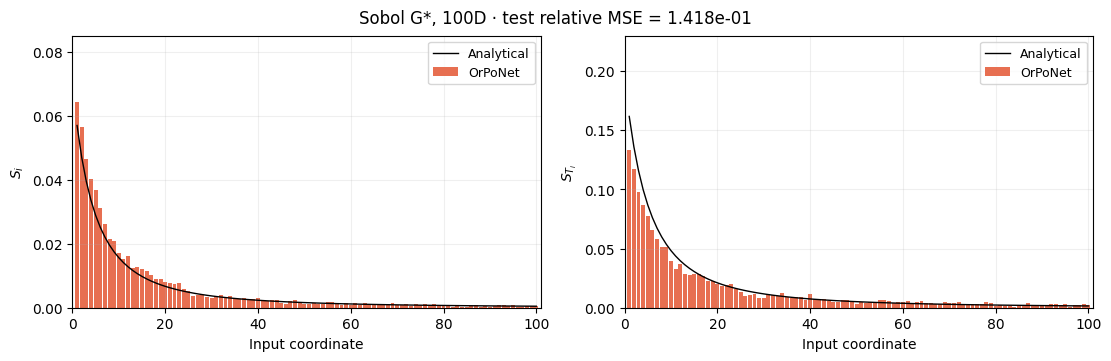

In [ ]:
coordinates = torch.arange(1, DIMENSION + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
axes[0].bar(
    coordinates,
    sobol["first_order"].cpu(),
    width=0.85,
    color="#E76F51",
    label="OrPoNet",
)
axes[0].plot(
    coordinates,
    reference_first.cpu(),
    color="black",
    linewidth=1.0,
    zorder=3,
    label="Analytical",
)

axes[0].set(
    xlabel="Input coordinate", ylabel=r"$S_i$", xlim=(0, DIMENSION + 1), ylim=(0, 0.085)
)
axes[0].set_yticks([0, 0.02, 0.04, 0.06, 0.08])
axes[0].grid(alpha=0.2)
axes[0].legend(fontsize=9)

axes[1].bar(
    coordinates,
    sobol["total_order"].cpu(),
    width=0.85,
    color="#E76F51",
    label="OrPoNet",
)
axes[1].plot(
    coordinates,
    reference_total.cpu(),
    color="black",
    linewidth=1.0,
    zorder=3,
    label="Analytical",
)

axes[1].set(
    xlabel="Input coordinate",
    ylabel=r"$S_{T_i}$",
    xlim=(0, DIMENSION + 1),
    ylim=(0, 0.23),
)
axes[1].set_yticks([0, 0.05, 0.10, 0.15, 0.20])
axes[1].grid(alpha=0.2)
axes[1].legend(fontsize=9)
fig.suptitle(f"Sobol G*, {DIMENSION}D · test relative MSE = {test_relative_mse:.3e}")
plt.show()
